<div align="center">

<h2><strong>PEMBUATAN RECIPE UNTUK SIMULASI DIFUSI PANAS SATU DIMENSI (ONE-DIMENSIONAL HEAT DIFFUSION SIMULATION)</strong></h2>
<h3><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h3>

<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h5><strong>Oleh:</strong></h5>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;"> 
  <li> 
    <strong>[PRITA LAURA PRISKILLA PONTENGI]</strong> 
    <div style="margin-top:10px;"> 
      <strong>[H061241047]</strong> 
    </div> 
  </li> 
</ul>

<p><strong>DEPARTEMEN GEOFISIKA</strong></p> 
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p> 
<p><strong>UNIVERSITAS HASANUDDIN</strong></p> 
<p><strong>2026</strong></p>

</div>

## **STUDI KASUS**

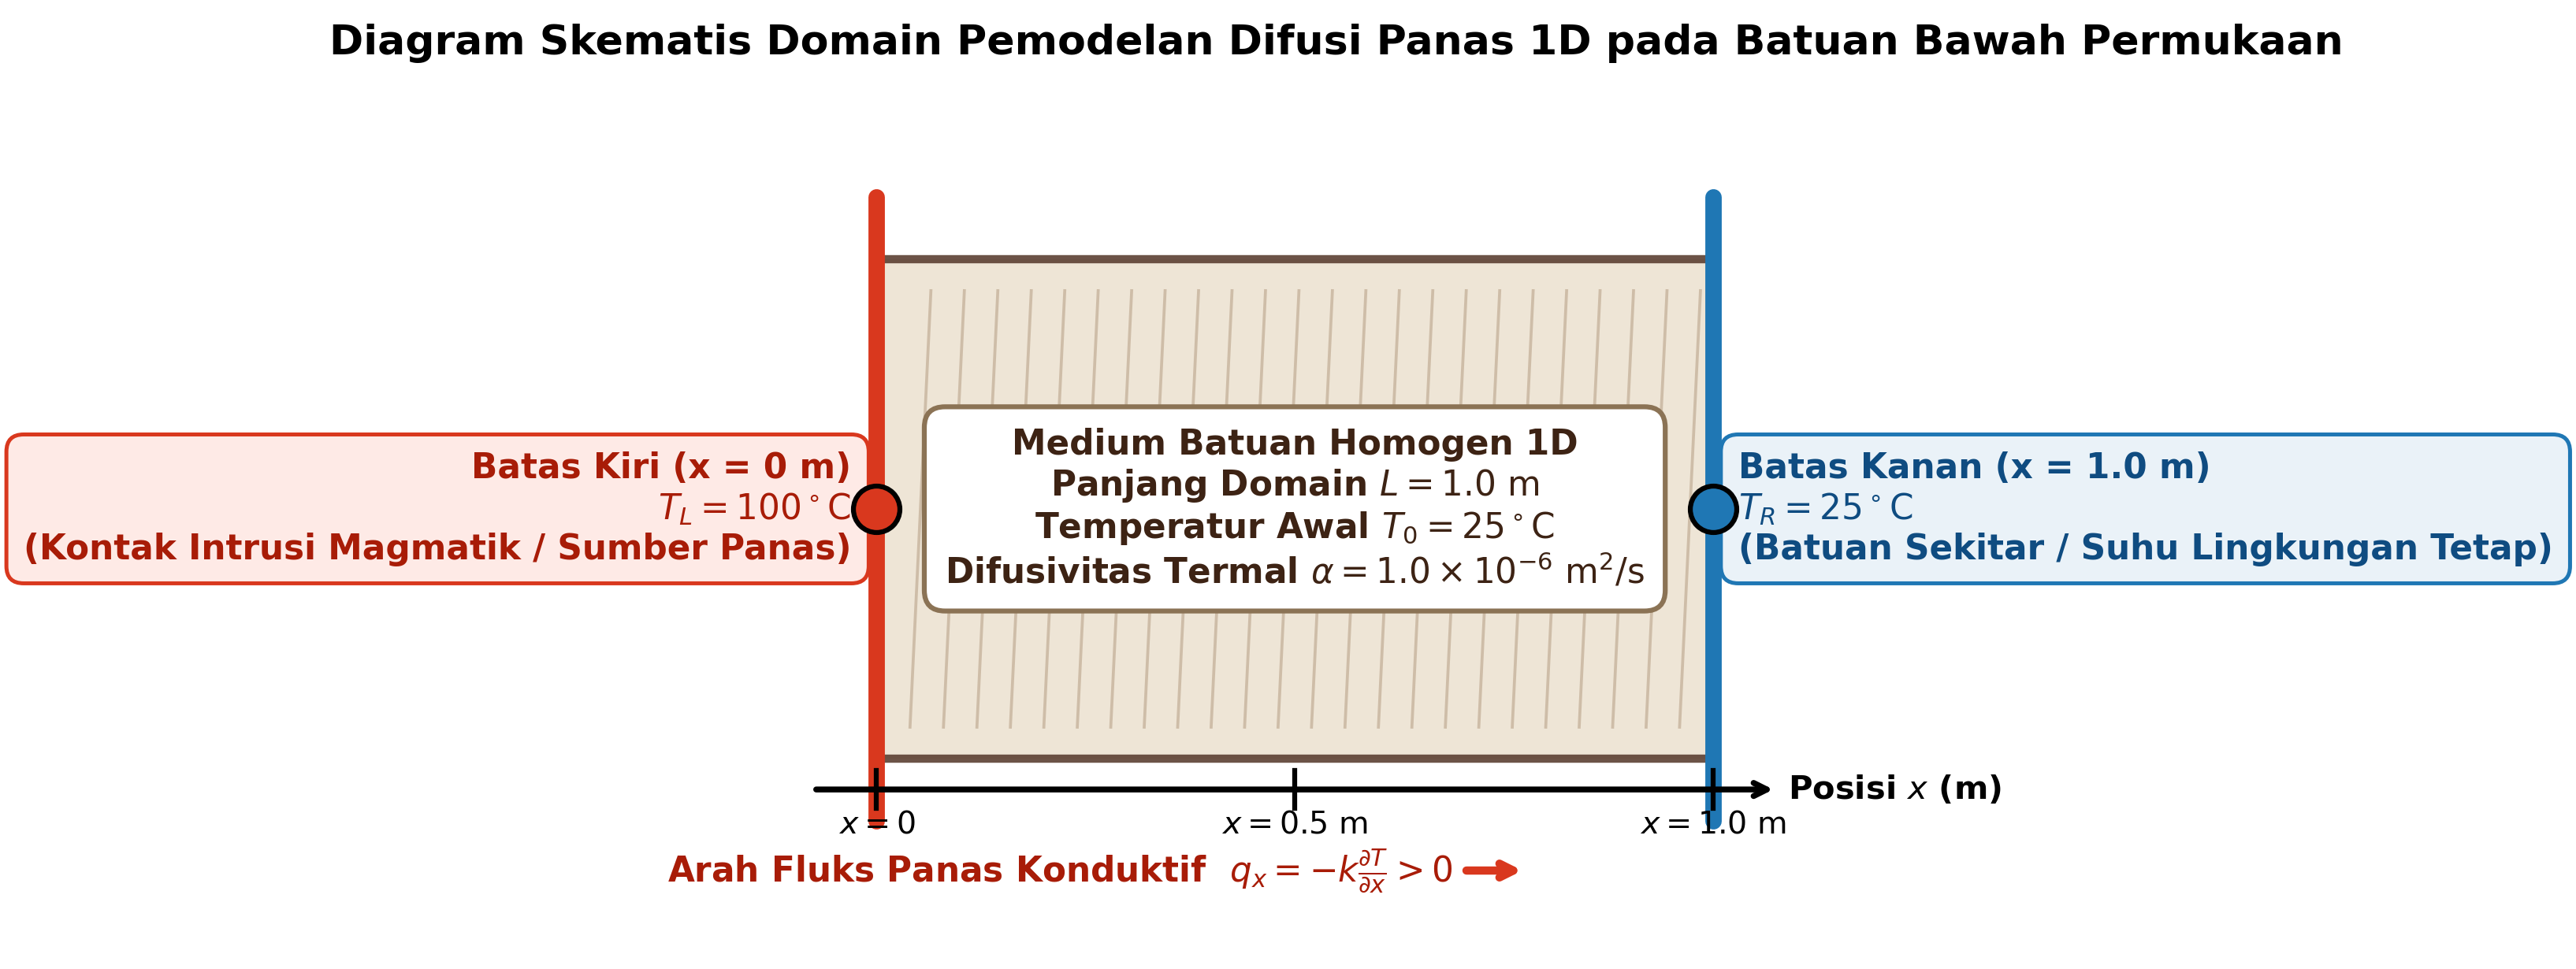

Dalam dinamika termal kerak bumi dan eksplorasi geofisika panas bumi (*geothermal*), pemahaman mengenai mekanisme perambatan temperatur di dalam media batuan merupakan aspek fundamental. Salah satu fenomena geologis yang paling sering dijumpai adalah proses transfer panas konduktif akibat adanya anomali termal lokal, seperti kontak tubuh intrusi batuan beku (*magma dike* atau *sill*) dengan formasi batuan samping (*host rock*), pemanasan pada dasar cekungan sedimen oleh batuan dasar kristalin (*crystalline basement*), atau rambatan panas pada dinding sumur injeksi geotermal.

Ketika tubuh intrusi magma bersuhu tinggi membeku dan bersentuhan langsung dengan lapisan batuan samping yang awalnya berada pada temperatur lingkungan yang lebih rendah, terbentuklah bidang diskontinuitas temperatur yang sangat curam tepat di zona kontak. Berdasarkan hukum termodinamika, energi termal akan mengalir secara spontan dari daerah bertemperatur tinggi menuju daerah bertemperatur rendah. Di dalam medium padat seperti batuan, proses transfer energi kinetik mikroskopis ini berlangsung melalui mekanisme konduksi termal (getaran kisi mineral atau *phonon conduction*) tanpa disertai perpindahan massa batuan itu sendiri. Fenomena perambatan dan perubahan distribusi temperatur terhadap ruang dan waktu inilah yang dikenal sebagai **proses difusi panas**.

Laju penyebaran dan profil distribusi temperatur di dalam batuan sangat dipengaruhi oleh sifat termofisik batuan penyusunnya, khususnya **difusivitas termal** ($\alpha$). Difusivitas termal merepresentasikan perbandingan antara kemampuan batuan dalam menghantarkan panas secara konduktif (*konduktivitas termal*, $k$) terhadap kapasitas volumetrik batuan dalam menyerap dan menyimpan energi termal per satuan perubahan temperatur (hasil kali massa jenis $\rho$ dan kapasitas kalor jenis $c_p$). Batuan dengan difusivitas termal yang tinggi akan meneruskan gelombang panas secara cepat, sementara batuan dengan difusivitas termal rendah bertindak sebagai isolator yang memperlambat perambatan muka panas.

Untuk menganalisis fenomena fisik ini secara kuantitatif dan terkontrol, dibangun sebuah skenario sintetik ideal berupa penampang batuan satu dimensi (1D) sepanjang $L = 1.0\ \mathrm{m}$. Medium batuan diinisialisasi pada kondisi awal bersuhu seragam $T_0 = 25.0^\circ\mathrm{C}$ (temperatur *ambient* bawah permukaan). Tepat pada saat awal simulasi ($t = 0$), batas sebelah kiri domain ($x = 0$) dikontakkan dengan sumber panas berkapasitas tak hingga yang dipertahankan konstan pada temperatur tinggi $T_L = 100.0^\circ\mathrm{C}$ (merepresentasikan kondisi kontak termal tunak dari tubuh intrusi). Sementara itu, batas sebelah kanan ($x = L = 1.0\ \mathrm{m}$) dipertahankan konstan pada temperatur lingkungan $T_R = 25.0^\circ\mathrm{C}$ (merepresentasikan kondisi batas luar atau permukaan bumi yang temperaturnya terjaga stabil).

### **Tujuan Simulasi**
1. **Mengembangkan dan Mengimplementasikan Model Numerik:** Membangun algoritma komputasi beda hingga eksplisit (*Forward-Time Central-Space* / FTCS) berbasis Python untuk memecahkan persamaan diferensial parsial difusi panas 1D.
2. **Mengamati Dinamika Fisis Difusi Panas:** Memvisualisasikan perambatan muka gelombang panas, peluruhan gradien temperatur tajam (*thermal gradient relaxation*), dan transisi dinamis dari kondisi transien awal menuju kondisi kesetimbangan tunak (*steady-state*).
3. **Menganalisis Respon Titik Pengamatan Interior:** Memeriksa kurva kenaikan temperatur terhadap waktu pada beberapa posisi spasial interior ($x = 0.10\ \mathrm{m}, 0.25\ \mathrm{m}, 0.50\ \mathrm{m}, 0.75\ \mathrm{m}$) guna memahami efek keterlambatan waktu (*time-lag*) akibat resistansi termal batuan.
4. **Validasi Kuantitatif dan Uji Akurasi:** Memverifikasi solusi numerik FTCS terhadap solusi analitik eksak deret Fourier (*Fourier Sine Series*) dan menghitung galat *Root Mean Square Error* (RMSE).

### **Rasionalisasi Model 1D dan Batasan Fisik**
Penggunaan model satu dimensi merupakan strategi metodologis untuk menyederhanakan kompleksitas geometri alamiah sehingga fokus investigasi terpusat pada interaksi murni antara difusivitas termal, gradien spasial, dan waktu difusi. Formulasi 1D memungkinkan penurunan solusi analitik eksak tertutup yang esensial sebagai pembanding mutu komputasi. 

Namun demikian, secara ilmiah perlu ditegaskan bahwa model sintetik 1D ini merupakan **penyederhanaan fisika idealisasi** untuk mempelajari proses difusi murni. Model ini **bukan** representasi lengkap dari sistem geotermal alamiah yang sesungguhnya di lapangan, di mana sistem geotermal nyata umumnya memiliki dimensi tiga (3D), heterogenitas litologi perlapisan yang tinggi, kehadiran jaringan kekar dan sesar (*fracture network*), sirkulasi hidrotermal fluida pori (adveksi/konveksi), serta produksi panas radiogenik internal ($Q \neq 0$).

## **DASAR TEORI DAN PERSAMAAN DIFUSI PANAS**

### **1. Hukum Fourier dan Persamaan Konservasi Energi**
Perpindahan kalor secara konduksi diatur oleh **Hukum Fourier**, yang menyatakan bahwa fluks panas konduktif ($q_x$) sebanding dengan gradien spasial temperatur, dengan arah aliran berlawanan dengan arah peningkatan temperatur:

$$q_x = -k \frac{\partial T}{\partial x}$$

di mana:
* $q_x$ adalah fluks panas per satuan luas ($\mathrm{W/m^2}$),
* $k$ adalah konduktivitas termal batuan ($\mathrm{W/(m\cdot K)}$),
* $\frac{\partial T}{\partial x}$ adalah gradien temperatur spasial ($^\circ\mathrm{C/m}$ atau $\mathrm{K/m}$).

Berdasarkan prinsip kekekalan energi (*conservation of thermal energy*) pada elemen volume diferensial berukuran $\Delta x$ dalam medium homogen tanpa adanya transfer massa (adveksi), perubahan energi dakhil persatuan waktu harus seimbang dengan selisih fluks panas bersih yang masuk dan keluar elemen:

$$\rho c_p \frac{\partial T}{\partial t} = -\frac{\partial q_x}{\partial x} + Q$$

Dengan mengasumsikan konduktivitas termal $k$ homogen dan tidak adanya sumber panas internal ($Q = 0$), substitusi Hukum Fourier ke dalam persamaan kekekalan energi menghasilkan **Persamaan Difusi Panas Satu Dimensi**:

$$\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial x^2}$$

dengan:
* $T(x, t)$ : temperatur sebagai fungsi posisi $x$ dan waktu $t$ ($^\circ\mathrm{C}$ atau $\mathrm{K}$),
* $x$ : koordinat spasial sepanjang medium ($\mathrm{m}$),
* $t$ : waktu elapsed simulasi ($\mathrm{s}$),
* $\alpha$ : difusivitas termal batuan ($\mathrm{m^2/s}$).

### **2. Hubungan Difusivitas Termal dengan Sifat Fisik Batuan**
Difusivitas termal ($\alpha$) didefinisikan secara matematis melalui hubungan:

$$\alpha = \frac{k}{\rho c_p}$$

di mana:
* $k$ : konduktivitas termal medium ($\mathrm{W/(m\cdot K)}$), yaitu parameter kemampuan menghantarkan panas,
* $\rho$ : massa jenis atau densitas batuan ($\mathrm{kg/m^3}$),
* $c_p$ : kapasitas kalor jenis batuan ($\mathrm{J/(kg\cdot K)}$), yaitu energi yang dibutuhkan untuk menaikkan suhu satu kilogram batuan sebesar satu kelvin.

Besaran $\rho c_p$ disebut sebagai **kapasitas panas volumetrik** (*volumetric heat capacity*, dalam $\mathrm{J/(m^3\cdot K)}$). Dalam studi geofisika, difusivitas termal batuan kerak bumi umumnya berkisar antara $0.5 \times 10^{-6}\ \mathrm{m^2/s}$ hingga $2.0 \times 10^{-6}\ \mathrm{m^2/s}$. Nilai sintetik yang diadopsi pada simulasi ini adalah $\alpha = 1.0 \times 10^{-6}\ \mathrm{m^2/s}$, yang merepresentasikan karakteristik batuan kerak padat seperti granit atau batupasir kompak.

| Jenis Batuan | Konduktivitas Termal, $k$ ($\mathrm{W/(m\cdot K)}$) | Densitas, $\rho$ ($\mathrm{kg/m^3}$) | Kapasitas Kalor, $c_p$ ($\mathrm{J/(kg\cdot K)}$) | Difusivitas Termal, $\alpha$ ($10^{-6}\ \mathrm{m^2/s}$) |
| :--- | :---: | :---: | :---: | :---: |
| **Granit (Granite)** | $2.5 - 3.2$ | $2600 - 2750$ | $790 - 840$ | $1.1 - 1.4$ |
| **Batupasir (Sandstone)** | $2.0 - 4.0$ | $2200 - 2600$ | $850 - 950$ | $1.0 - 1.6$ |
| **Basal (Basalt)** | $1.7 - 2.2$ | $2800 - 3000$ | $840 - 900$ | $0.7 - 0.9$ |
| **Serpih (Shale)** | $1.2 - 2.0$ | $2300 - 2600$ | $900 - 1000$ | $0.5 - 0.8$ |
| **Model Sintetik Ini** | **$2.50$** | **$2500$** | **$1000$** | **$1.00$** |

### **3. Asumsi Model Secara Eksplisit**
Implementasi komputasi ini dibangun di atas serangkaian asumsi fisis penyederhanaan yang ditegaskan secara eksplisit:
1. **Medium Homogen dan Isotropik:** Sifat termofisik batuan ($k, \rho, c_p$) diasumsikan seragam di seluruh titik spasial dan memiliki nilai yang identik ke segala arah.
2. **Difusivitas Termal Konstan:** Nilai $\alpha$ bernilai tetap ($1.0 \times 10^{-6}\ \mathrm{m^2/s}$) dan tidak berubah sepanjang durasi simulasi.
3. **Perpindahan Panas Konduksi 1D Murni:** Kalor hanya merambat sepanjang satu dimensi spasial (sumbu $x$). Tidak ada fluks panas lateral atau disipasi energi ke arah sumbu $y$ dan $z$.
4. **Tidak Ada Sumber Panas Internal ($Q = 0$):** Model mengabaikan kontribusi panas peluruhan radioaktif alami isotop batuan ($^{238}\mathrm{U}, ^{232}\mathrm{Th}, ^{40}\mathrm{K}$) maupun reaksi kimia metamorfisme.
5. **Sifat Termal Independen terhadap Temperatur:** Variasi temperatur selama proses difusi ($25^\circ\mathrm{C}$ hingga $100^\circ\mathrm{C}$) diasumsikan tidak mempengaruhi konduktivitas maupun kapasitas panas batuan.
6. **Tidak Ada Aliran Fluida (Tanpa Adveksi):** Batuan dianggap memiliki permeabilitas nol atau fluida pori bersifat statis, sehingga transfer kalor murni difusif tanpa bantuan sirkulasi hidrotermal.
7. **Penyederhanaan Kondisi Batuan Nyata:** Asumsi-asumsi di atas menyederhanakan sistem geologi alamiah yang sebenarnya kompleks dan heterogen demi memfasilitasi formulasi matematis yang terverifikasi.

## **MODEL NUMERIK DAN DISKRETISASI FTCS**

### **1. Diskretisasi Domain Spasial dan Temporal**
Untuk memecahkan persamaan diferensial parsial difusi panas secara komputasi, domain kontinu ruang-waktu $(x, t)$ didiskretisasi ke dalam kisi kisi beraturan (*regular grid*):
* Sumbu spasial sepanjang domain $L$ dibagi menjadi $N_x$ titik kisi dengan spasi seragam:
  $$x_i = i \Delta x, \quad i = 0, 1, 2, \dots, N_x - 1, \quad \text{dengan } \Delta x = \frac{L}{N_x - 1}$$
* Sumbu temporal dari $t = 0$ hingga $t_{\max}$ dibagi menjadi $N_t$ langkah waktu dengan inkremen:
  $$t_n = n \Delta t, \quad n = 0, 1, 2, \dots, N_t - 1, \quad \text{dengan } \Delta t = \frac{t_{\max}}{N_t - 1}$$
* Notasi nilai temperatur pada titik ruang ke-$i$ dan langkah waktu ke-$n$ dilambangkan sebagai:
  $$T_i^n \approx T(x_i, t_n)$$

### **2. Formulasi Beda Hingga Eksplisit (FTCS)**
Metode **Forward-Time Central-Space (FTCS)** menggunakan pendekatan beda maju (*forward difference*) berorde satu untuk turunan waktu dan beda pusat (*central difference*) berorde dua untuk turunan ruang:
* **Aproksimasi Turunan Waktu:**
  $$\left. \frac{\partial T}{\partial t} \right|_i^n = \frac{T_i^{n+1} - T_i^n}{\Delta t} + \mathcal{O}(\Delta t)$$
* **Aproksimasi Turunan Ruang Orde Dua:**
  $$\left. \frac{\partial^2 T}{\partial x^2} \right|_i^n = \frac{T_{i+1}^n - 2T_i^n + T_{i-1}^n}{(\Delta x)^2} + \mathcal{O}((\Delta x)^2)$$

Substitusi kedua ekspresi diskrit tersebut ke dalam persamaan difusi panas satu dimensi:
$$\frac{T_i^{n+1} - T_i^n}{\Delta t} = \alpha \left[ \frac{T_{i+1}^n - 2T_i^n + T_{i-1}^n}{(\Delta x)^2} \right]$$

Dengan melakukan penyusunan ulang persamaan untuk mengisolasi suku temperatur pada langkah waktu masa depan ($T_i^{n+1}$), diperoleh formula rekursif eksplisit:
$$T_i^{n+1} = T_i^n + r \left(T_{i+1}^n - 2T_i^n + T_{i-1}^n\right)$$

di mana $r$ adalah **parameter kestabilan difusi numerik** tak berdimensi (*diffusion Courant-like number*):
$$r = \frac{\alpha \Delta t}{(\Delta x)^2}$$

Formula di atas menunjukkan bahwa nilai temperatur pada titik interior ke-$i$ pada langkah waktu berikutnya ($n+1$) dihitung secara langsung (*eksplisit*) dari kombinasi linier temperatur titik tetangga ($i-1, i, i+1$) pada langkah waktu saat ini ($n$).

### **3. Kriteria Kestabilan Numerik Von Neumann**
Skema numerik FTCS bersifat stabil kondisional (*conditionally stable*). Berdasarkan analisis kestabilan Von Neumann, solusi gelombang kesalahan $T_i^n = \xi^n e^{I k_x i \Delta x}$ memiliki faktor amplifikasi:
$$\xi = 1 - 4r \sin^2\left(\frac{k_x \Delta x}{2}\right)$$

Agar kesalahan numerik dan galat pembulatan mesin (*round-off errors*) tidak teramplifikasi secara eksponensial seiring bertambahnya waktu simulasi, disyaratkan kondisi keterikatan magnitudo amplifikasi:
$$|\xi| \le 1 \quad \Longrightarrow \quad -1 \le 1 - 4r \le 1 \quad \Longrightarrow \quad r \le \frac{1}{2}$$

Konsekuensi matematis dari syarat kestabilan ini menetapkan batas maksimum langkah waktu temporal yang diizinkan untuk spasi spasial $\Delta x$ tertentu:
$$\Delta t \le \frac{(\Delta x)^2}{2\alpha}$$

Jika kondisi $r \le 0.5$ dipenuhi, skema FTCS dijamin stabil, menghasilkan solusi aproksimasi yang konvergen dan bebas osilasi palsu. Sebaliknya, apabila $r > 0.5$, simulasi akan mengalami ketidakstabilan numerik (*numerical blow-up*) yang ditandai dengan osilasi tak hingga dan nilai NaN (*Not a Number*). Oleh karena itu, simulasi ini dilengkapi dengan modul pemeriksaan otomatis (*automated stability guard*) sebelum algoritma utama dieksekusi.

### **4. Penerapan Kondisi Batas Dirichlet**
Pada setiap iterasi waktu $n+1$, kondisi batas temperatur tetap (*Dirichlet boundary conditions*) diterapkan secara ketat pada kedua ujung domain spasial:
* Batas kiri ($x = 0$, indeks $i = 0$):
  $$T_0^{n+1} = T_L = 100.0^\circ\mathrm{C}$$
* Batas kanan ($x = L$, indeks $i = N_x - 1$):
  $$T_{N_x-1}^{n+1} = T_R = 25.0^\circ\mathrm{C}$$

Hanya titik-titik interior ($i = 1, 2, \dots, N_x - 2$) yang diperbarui menggunakan skema FTCS pada setiap iterasi waktu.

In [1]:
# ==============================================================================
# 1. IMPORT PUSTAKA SAINTIFIK & KONFIGURASI GRAFIK
# ==============================================================================
import sys
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Memastikan output karakter konsol UTF-8 berjalan baik pada sistem Windows
if sys.platform == "win32":
    try:
        sys.stdout.reconfigure(encoding="utf-8")
        sys.stderr.reconfigure(encoding="utf-8")
    except Exception:
        pass

# Konfigurasi gaya tampilan grafik Matplotlib standar publikasi ilmiah
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10.0
plt.rcParams['axes.titlesize'] = 11.5
plt.rcParams['axes.labelsize'] = 10.5
plt.rcParams['xtick.labelsize'] = 9.5
plt.rcParams['ytick.labelsize'] = 9.5
plt.rcParams['legend.fontsize'] = 9.5
plt.rcParams['figure.titlesize'] = 13.0
plt.rcParams['lines.linewidth'] = 1.8
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['grid.linestyle'] = '--'

print(f"[STATUS] Pustaka NumPy {np.__version__} dan Matplotlib {plt.matplotlib.__version__} berhasil dimuat.")


[STATUS] Pustaka NumPy 2.3.5 dan Matplotlib 3.10.8 berhasil dimuat.


In [2]:
# ==============================================================================
# 2. DEFINISI PARAMETER MODEL FISIS & DISKRETISASI GRID SPASIOTEMPORAL
# ==============================================================================

# --- Parameter Geometri Domain Batuan ---
L = 1.0                # Panjang domain batuan satu dimensi (meter)
Nx = 101               # Jumlah titik kisi spasial sepanjang domain
dx = L / (Nx - 1)      # Spasi grid spasial (Delta x = 0.01 m = 1 cm)
x = np.linspace(0.0, L, Nx)  # Array koordinat posisi spasial (meter)

# --- Parameter Fisika Termal Batuan ---
# Difusivitas termal batuan kerak bumi tipikal (granit/batupasir kompak)
# alpha = k / (rho * c_p)
alpha = 1.0e-6         # Difusivitas termal batuan (m^2/s)

# --- Parameter Kondisi Batas & Awal ---
T0 = 25.0              # Temperatur awal seragam medium batuan (derajat Celsius)
T_L = 100.0            # Temperatur batas kiri (x = 0 m): kontak intrusi magmatik (deg C)
T_R = 25.0             # Temperatur batas kanan (x = 1 m): lingkungan sekitar (deg C)

# --- Parameter Waktu Simulasi ---
t_max = 100000.0       # Durasi total simulasi termal (sekon) ~ 27.78 jam
dt = 40.0              # Langkah waktu integrasi numerik (Delta t, sekon)
r = alpha * dt / (dx**2) # Parameter kestabilan difusi numerik tak berdimensi

# Menghitung jumlah langkah waktu temporal
Nt = int(np.round(t_max / dt)) + 1
t = np.linspace(0.0, t_max, Nt)

print("=" * 70)
print("           KONFIGURASI PARAMETER SIMULASI DIFUSI PANAS 1D")
print("=" * 70)
print(f"Panjang Domain Batuan (L)           : {L:.2f} m")
print(f"Jumlah Titik Spasial (Nx)           : {Nx} titik")
print(f"Resolusi Grid Spasial (dx)          : {dx:.4f} m ({dx*100:.1f} cm)")
print(f"Difusivitas Termal (alpha)          : {alpha:.2e} m^2/s")
print(f"Temperatur Awal Batuan (T0)         : {T0:.1f} deg C")
print(f"Kondisi Batas Kiri (T_L di x=0)     : {T_L:.1f} deg C (Intrusi Magma)")
print(f"Kondisi Batas Kanan (T_R di x=L)    : {T_R:.1f} deg C (Ambient Luar)")
print(f"Durasi Total Simulasi (t_max)       : {t_max:.1f} s ({t_max/3600:.2f} jam)")
print(f"Langkah Waktu Integrasi (dt)        : {dt:.1f} s")
print(f"Jumlah Langkah Waktu (Nt)           : {Nt} langkah")
print(f"Parameter Difusi Numerik (r)        : {r:.4f}")
print("=" * 70)


           KONFIGURASI PARAMETER SIMULASI DIFUSI PANAS 1D
Panjang Domain Batuan (L)           : 1.00 m
Jumlah Titik Spasial (Nx)           : 101 titik
Resolusi Grid Spasial (dx)          : 0.0100 m (1.0 cm)
Difusivitas Termal (alpha)          : 1.00e-06 m^2/s
Temperatur Awal Batuan (T0)         : 25.0 deg C
Kondisi Batas Kiri (T_L di x=0)     : 100.0 deg C (Intrusi Magma)
Kondisi Batas Kanan (T_R di x=L)    : 25.0 deg C (Ambient Luar)
Durasi Total Simulasi (t_max)       : 100000.0 s (27.78 jam)
Langkah Waktu Integrasi (dt)        : 40.0 s
Jumlah Langkah Waktu (Nt)           : 2501 langkah
Parameter Difusi Numerik (r)        : 0.4000


In [3]:
# ==============================================================================
# 3. PEMERIKSAAN KESTABILAN NUMERIK OTOMATIS (STABILITY GUARD)
# ==============================================================================

def check_ftcs_stability(alpha_val, dx_val, dt_val):
    """
    Fungsi guard untuk memverifikasi kriteria kestabilan Von Neumann 
    skema FTCS pada persamaan difusi panas 1D:
    r = alpha * dt / (dx^2) <= 0.5
    """
    r_val = alpha_val * dt_val / (dx_val**2)
    dt_max_stable = 0.5 * (dx_val**2) / alpha_val
    
    print("-" * 70)
    print("         PEMERIKSAAN KESTABILAN NUMERIK VON NEUMANN (FTCS)")
    print("-" * 70)
    print(f"Nilai Parameter Difusi (r)         : {r_val:.5f}")
    print(f"Batas Maksimum Kestabilan (r_crit) : 0.50000")
    print(f"Langkah Waktu Maksimum (dt_max)    : {dt_max_stable:.2f} s")
    print(f"Langkah Waktu Dipilih (dt)         : {dt_val:.2f} s")
    
    if r_val <= 0.5:
        margin = (0.5 - r_val) / 0.5 * 100
        print(f"[STATUS: STABIL] Parameter r = {r_val:.4f} <= 0.5.")
        print(f"Simulasi memenuhi syarat kestabilan (Safety margin: {margin:.1f}% di bawah batas kritis).")
        print("Algoritma FTCS dijamin konvergen tanpa osilasi divergensi.")
        print("-" * 70)
        return True
    else:
        print(f"[ERROR: TIDAK STABIL] Parameter r = {r_val:.4f} > 0.5!")
        print("Peringatan: Skema eksplisit FTCS akan mengalami divergensi numerik (blow-up).")
        print(f"Saran Koreksi:")
        print(f"  1. Kurangi Delta t hingga dt <= {dt_max_stable:.2f} sekon.")
        print(f"  2. Atau perbesar Delta x sehingga dx >= {np.sqrt(2 * alpha_val * dt_val):.4f} meter.")
        print("-" * 70)
        raise ValueError(f"Kondisi kestabilan FTCS dilanggar: r = {r_val:.4f} > 0.5!")

# Eksekusi pemeriksaan kestabilan numerik
is_stable = check_ftcs_stability(alpha, dx, dt)


----------------------------------------------------------------------
         PEMERIKSAAN KESTABILAN NUMERIK VON NEUMANN (FTCS)
----------------------------------------------------------------------
Nilai Parameter Difusi (r)         : 0.40000
Batas Maksimum Kestabilan (r_crit) : 0.50000
Langkah Waktu Maksimum (dt_max)    : 50.00 s
Langkah Waktu Dipilih (dt)         : 40.00 s
[STATUS: STABIL] Parameter r = 0.4000 <= 0.5.
Simulasi memenuhi syarat kestabilan (Safety margin: 20.0% di bawah batas kritis).
Algoritma FTCS dijamin konvergen tanpa osilasi divergensi.
----------------------------------------------------------------------


In [4]:
# ==============================================================================
# 4. INISIALISASI KONDISI AWAL & PENERAPAN KONDISI BATAS DIRICHLET
# ==============================================================================

# Membuat matriks 2D untuk menyimpan evolusi spasiotemporal temperatur:
# Dimensi matriks: (Nt baris x Nx kolom)
# Baris merepresentasikan indeks langkah waktu (t_n), kolom merepresentasikan posisi spasial (x_i)
T = np.zeros((Nt, Nx), dtype=np.float64)

# Menetapkan kondisi awal seragam pada seluruh domain batuan pada t = 0
T[0, :] = T0

# Menerapkan kondisi batas Dirichlet tetap pada t = 0
T[0, 0] = T_L    # Batas kiri (x = 0 m): 100.0 °C
T[0, -1] = T_R   # Batas kanan (x = 1.0 m): 25.0 °C

print(f"[STATUS] Matriks solusi T(Nt, Nx) berukuran {T.shape} berhasil diinisialisasi.")
print(f"Temperatur Awal Minimum             : {np.min(T[0, :]):.2f} deg C")
print(f"Temperatur Awal Maksimum            : {np.max(T[0, :]):.2f} deg C")
print(f"Temperatur Batas Kiri (x=0, t=0)    : {T[0, 0]:.2f} deg C")
print(f"Temperatur Batas Kanan (x=L, t=0)   : {T[0, -1]:.2f} deg C")
print(f"Temperatur Titik Interior (x=0.5m)  : {T[0, int(Nx/2)]:.2f} deg C")


[STATUS] Matriks solusi T(Nt, Nx) berukuran (2501, 101) berhasil diinisialisasi.
Temperatur Awal Minimum             : 25.00 deg C
Temperatur Awal Maksimum            : 100.00 deg C
Temperatur Batas Kiri (x=0, t=0)    : 100.00 deg C
Temperatur Batas Kanan (x=L, t=0)   : 25.00 deg C
Temperatur Titik Interior (x=0.5m)  : 25.00 deg C


In [5]:
# ==============================================================================
# 5. IMPLEMENTASI SOLVER FTCS & EKSEKUSI SIMULASI DIFUSI PANAS
# ==============================================================================

# Menentukan indeks waktu representatif untuk perekaman snapshot profil spasial:
# 0% (awal), 25%, 50%, 75%, dan 100% (akhir durasi simulasi)
snapshot_fractions = [0.0, 0.25, 0.50, 0.75, 1.0]
snapshot_indices = [int(round(f * (Nt - 1))) for f in snapshot_fractions]
snapshot_times = [t[idx] for idx in snapshot_indices]

print("Menjalankan integrasi temporal FTCS untuk difusi panas 1D...")
start_time = time.time()

# Iterasi integrasi waktu dari n = 0 hingga Nt - 2
for n in range(0, Nt - 1):
    # Pembaruan titik interior (i = 1 hingga Nx - 2) secara tervetor
    # T_i^{n+1} = T_i^n + r * (T_{i+1}^n - 2*T_i^n + T_{i-1}^n)
    T[n + 1, 1:-1] = T[n, 1:-1] + r * (T[n, 2:] - 2.0 * T[n, 1:-1] + T[n, :-2])
    
    # Penerapan kondisi batas Dirichlet pada langkah waktu baru n+1
    T[n + 1, 0] = T_L     # Batas kiri konstan 100 °C
    T[n + 1, -1] = T_R    # Batas kanan konstan 25 °C

elapsed_time = time.time() - start_time
print(f"[SELESAI] Komputasi FTCS {Nt} langkah waktu rampung dalam {elapsed_time:.3f} detik.")
print("-" * 70)
print("WAKTU SNAPSHOT REPRESENTATIF YANG DICATAT:")
for frac, idx, t_val in zip(snapshot_fractions, snapshot_indices, snapshot_times):
    print(f"  * Snapshot {frac*100:5.1f}% : Langkah waktu n = {idx:4d} | Waktu aktual t = {t_val:8.1f} s ({t_val/3600:5.2f} jam)")
print("-" * 70)


Menjalankan integrasi temporal FTCS untuk difusi panas 1D...
[SELESAI] Komputasi FTCS 2501 langkah waktu rampung dalam 0.030 detik.
----------------------------------------------------------------------
WAKTU SNAPSHOT REPRESENTATIF YANG DICATAT:
  * Snapshot   0.0% : Langkah waktu n =    0 | Waktu aktual t =      0.0 s ( 0.00 jam)
  * Snapshot  25.0% : Langkah waktu n =  625 | Waktu aktual t =  25000.0 s ( 6.94 jam)
  * Snapshot  50.0% : Langkah waktu n = 1250 | Waktu aktual t =  50000.0 s (13.89 jam)
  * Snapshot  75.0% : Langkah waktu n = 1875 | Waktu aktual t =  75000.0 s (20.83 jam)
  * Snapshot 100.0% : Langkah waktu n = 2500 | Waktu aktual t = 100000.0 s (27.78 jam)
----------------------------------------------------------------------


[SUKSES] Visualisasi utama 4-panel berhasil dibuat dan disimpan ke 'simulasi_difusi_panas_1d_fig.png'.


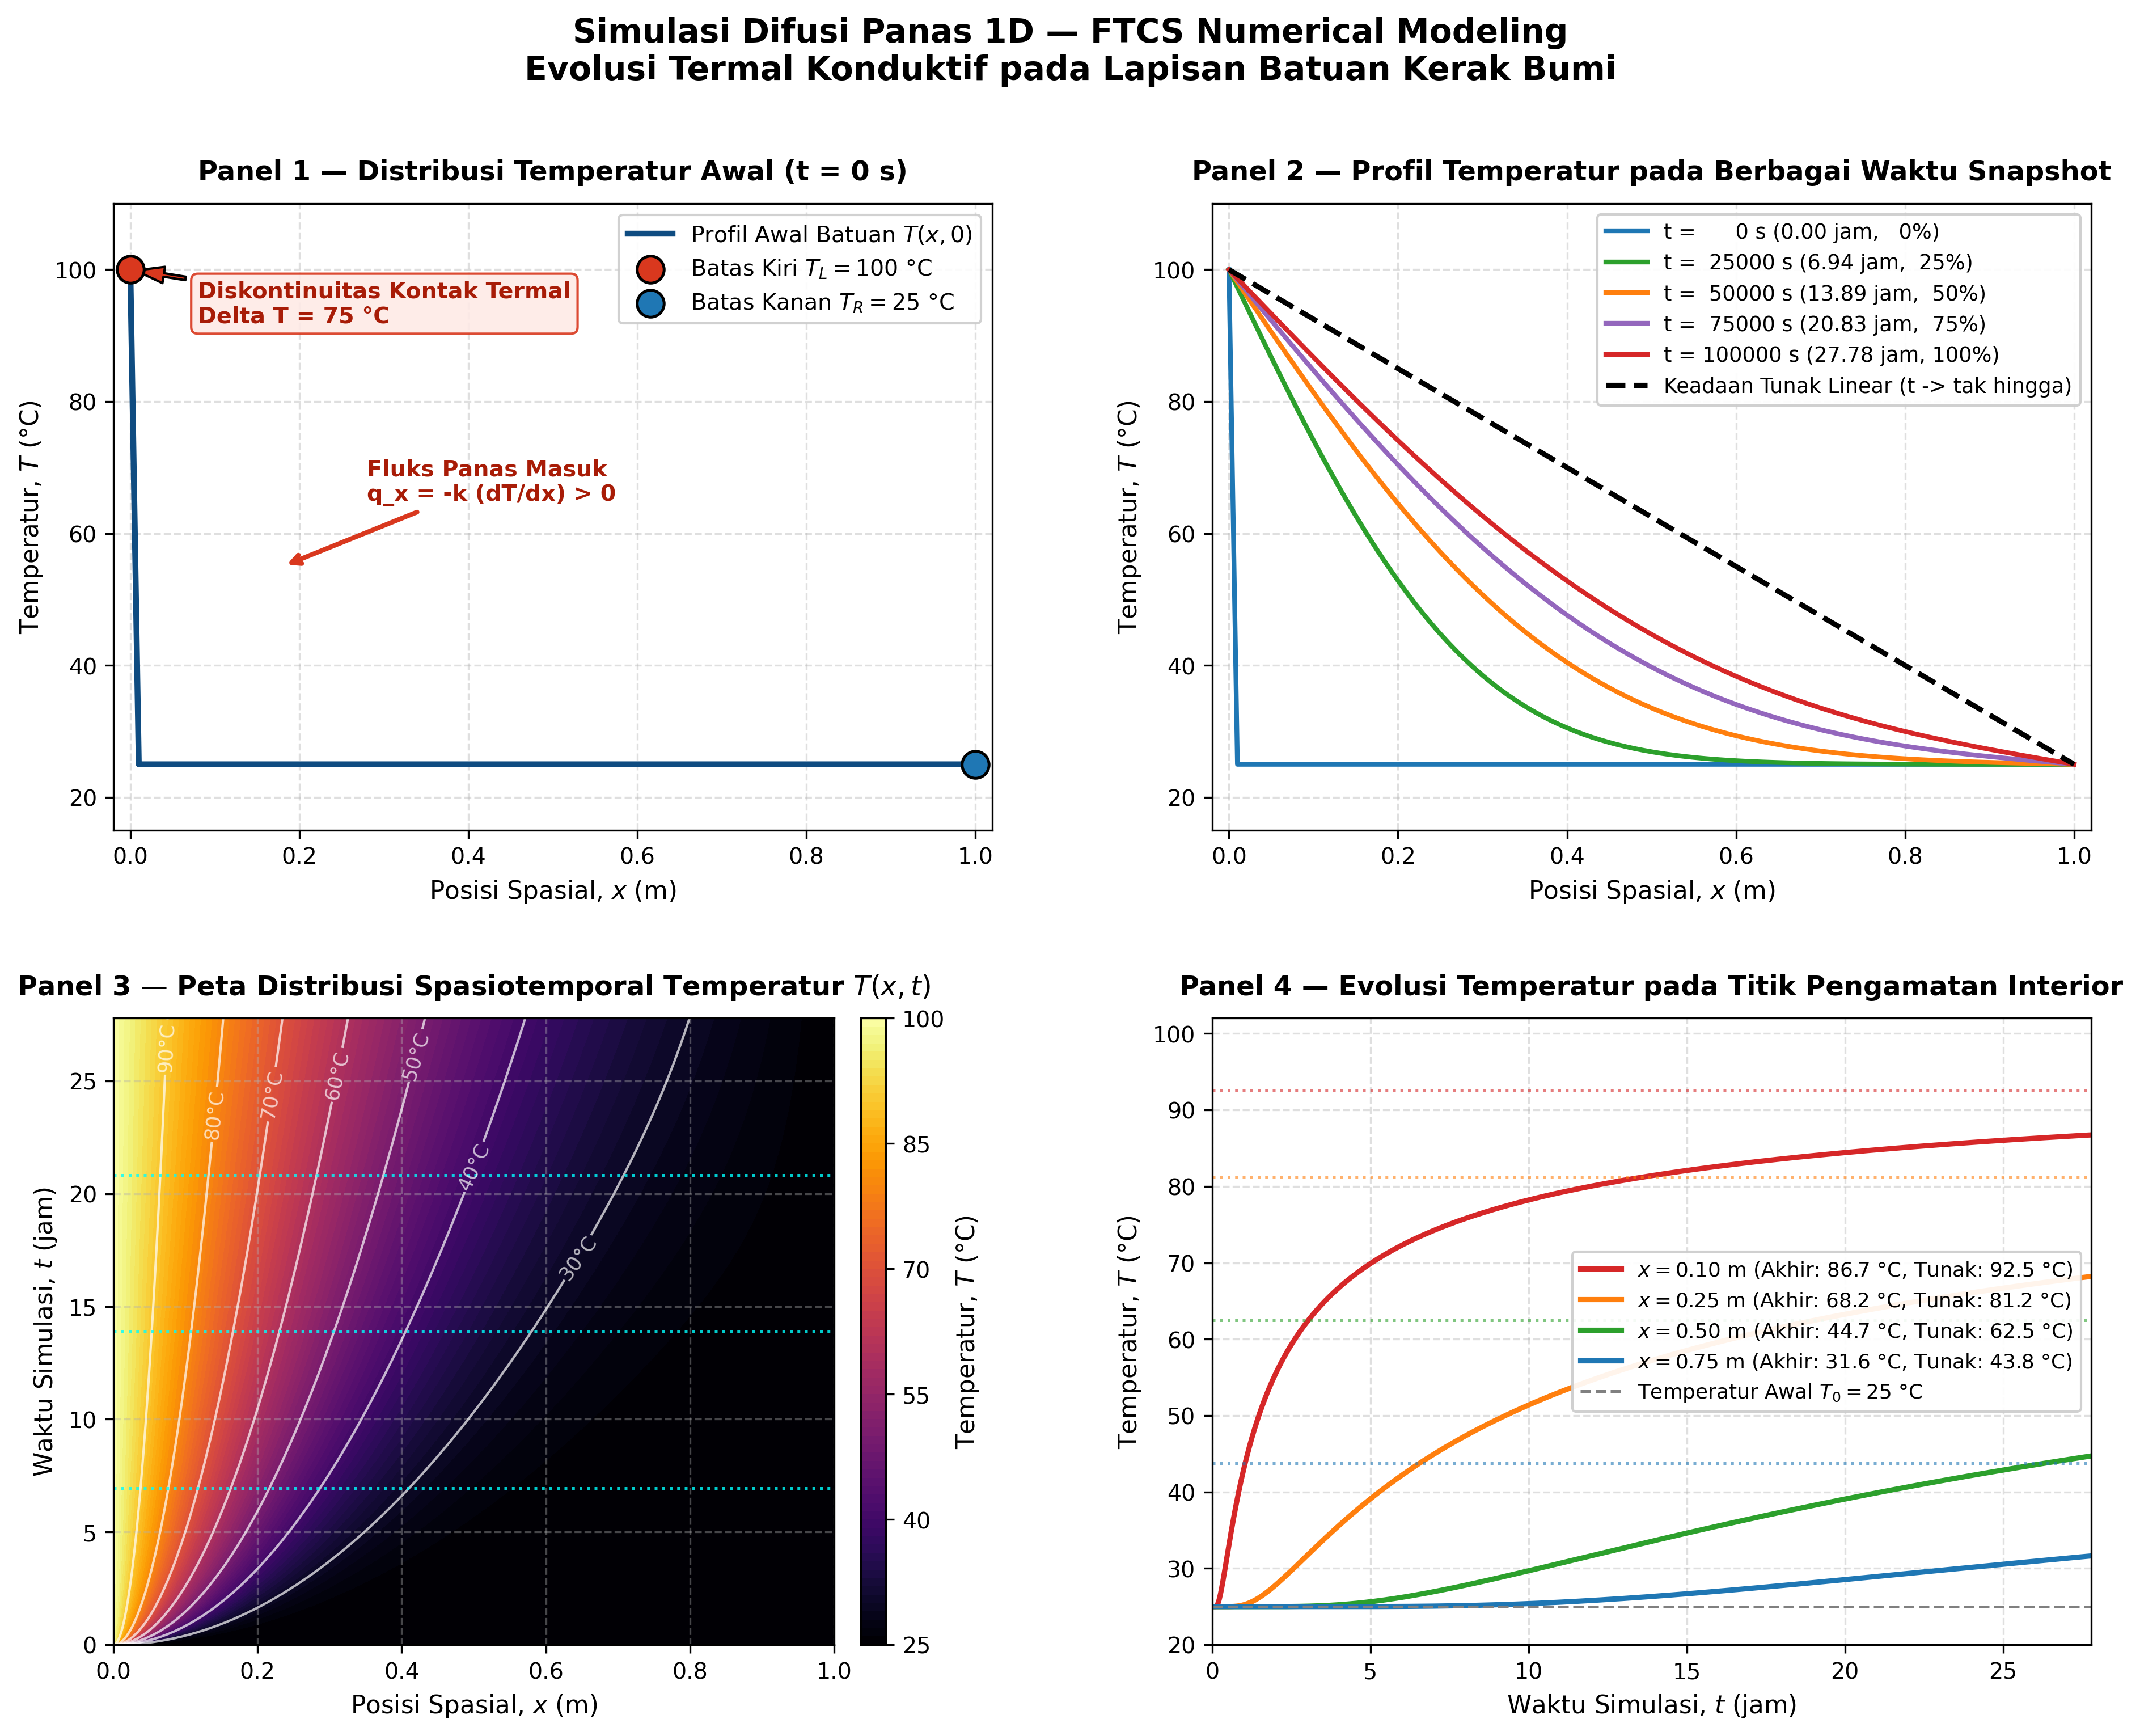

In [6]:
# ==============================================================================
# 6. VISUALISASI HASIL SIMULASI (FIGUR UTAMA 4-PANEL PUBLICATION-GRADE)
# ==============================================================================

# Membuat figur komprehensif 4-panel (2 baris x 2 kolom)
fig = plt.figure(figsize=(15, 11), dpi=300)
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.30, wspace=0.25)

# Palet warna kurva temporal snapshot
colors = ['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd', '#d62728']

# ------------------------------------------------------------------------------
# PANEL 1: DISTRIBUSI TEMPERATUR AWAL (t = 0 s)
# ------------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(x, T[0, :], color='#0f4c81', lw=2.5, label='Profil Awal Batuan $T(x, 0)$')
ax1.scatter([0.0], [T_L], color='#d9381e', s=130, zorder=5, edgecolor='black', lw=1.2,
            label=f'Batas Kiri $T_L = {T_L:.0f}$ °C')
ax1.scatter([1.0], [T_R], color='#1f77b4', s=130, zorder=5, edgecolor='black', lw=1.2,
            label=f'Batas Kanan $T_R = {T_R:.0f}$ °C')

# Anotasi kondisi batas dan aliran fluks
ax1.annotate("Diskontinuitas Kontak Termal\nDelta T = 75 °C", 
             xy=(0.0, 100.0), xytext=(0.08, 92.0),
             arrowprops=dict(facecolor='#d9381e', shrink=0.08, width=1.5, headwidth=7),
             fontsize=9.5, fontweight='bold', color='#a81c07',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#feeae6', edgecolor='#d9381e', alpha=0.9))

ax1.annotate("Fluks Panas Masuk\nq_x = -k (dT/dx) > 0", 
             xy=(0.18, 55.0), xytext=(0.28, 65.0),
             arrowprops=dict(arrowstyle='->', lw=2.0, color='#d9381e'),
             fontsize=9.5, fontweight='bold', color='#a81c07')

ax1.set_title("Panel 1 — Distribusi Temperatur Awal (t = 0 s)", fontweight='bold', pad=10)
ax1.set_xlabel("Posisi Spasial, $x$ (m)")
ax1.set_ylabel("Temperatur, $T$ (°C)")
ax1.set_xlim(-0.02, 1.02)
ax1.set_ylim(15.0, 110.0)
ax1.legend(loc='upper right', framealpha=0.9)

# ------------------------------------------------------------------------------
# PANEL 2: PROFIL TEMPERATUR PADA BEBERAPA WAKTU REPRESENTATIF
# ------------------------------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])

# Plot kurva untuk setiap snapshot waktu
for idx, color in zip(snapshot_indices, colors):
    t_sec = t[idx]
    t_hr = t_sec / 3600.0
    pct = (t_sec / t_max) * 100.0
    label_str = f"t = {t_sec:6.0f} s ({t_hr:4.2f} jam, {pct:3.0f}%)"
    ax2.plot(x, T[idx, :], color=color, lw=2.0, label=label_str)

# Solusi keadaan tunak (Steady-State Linear Profile): T_ss(x) = T_L + (T_R - T_L)*(x/L)
T_steady = T_L + (T_R - T_L) * (x / L)
ax2.plot(x, T_steady, 'k--', lw=2.2, label='Keadaan Tunak Linear (t -> tak hingga)')

ax2.set_title("Panel 2 — Profil Temperatur pada Berbagai Waktu Snapshot", fontweight='bold', pad=10)
ax2.set_xlabel("Posisi Spasial, $x$ (m)")
ax2.set_ylabel("Temperatur, $T$ (°C)")
ax2.set_xlim(-0.02, 1.02)
ax2.set_ylim(15.0, 110.0)
ax2.legend(loc='upper right', fontsize=8.8, framealpha=0.92)

# ------------------------------------------------------------------------------
# PANEL 3: PETA SPASIOTEMPORAL DISTRIBUSI TEMPERATUR (HEATMAP / CONTOUR)
# ------------------------------------------------------------------------------
ax3 = fig.add_subplot(gs[1, 0])

# Konversi sumbu waktu ke satuan jam untuk visualisasi geofisika yang representatif
time_hours = t / 3600.0
X_mesh, T_mesh = np.meshgrid(x, time_hours)

# Heatmap kontur temperatur beresolusi tinggi menggunakan colormap 'inferno'
contour_levels = np.linspace(25.0, 100.0, 76)
pcm = ax3.contourf(X_mesh, T_mesh, T, levels=contour_levels, cmap='inferno')

# Garis kontur isotermal bertingkat
line_levels = [30.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0]
cs = ax3.contour(X_mesh, T_mesh, T, levels=line_levels, colors='white', linewidths=1.0, alpha=0.7)
ax3.clabel(cs, inline=True, fmt='%1.0f°C', fontsize=8.5, colors='white')

# Garis horizontal menandai waktu snapshot
for s_idx in snapshot_indices[1:-1]:
    ax3.axhline(y=time_hours[s_idx], color='cyan', linestyle=':', lw=1.2, alpha=0.8)

ax3.set_title("Panel 3 — Peta Distribusi Spasiotemporal Temperatur $T(x, t)$", fontweight='bold', pad=10)
ax3.set_xlabel("Posisi Spasial, $x$ (m)")
ax3.set_ylabel("Waktu Simulasi, $t$ (jam)")
ax3.set_xlim(0.0, 1.0)
ax3.set_ylim(0.0, t_max / 3600.0)

# Menambahkan colorbar temperatur dengan label jelas
cbar = fig.colorbar(pcm, ax=ax3, orientation='vertical', pad=0.03, aspect=25)
cbar.set_label("Temperatur, $T$ (°C)", fontsize=10.5)
cbar.set_ticks(np.linspace(25.0, 100.0, 6))

# ------------------------------------------------------------------------------
# PANEL 4: PERUBAHAN TEMPERATUR PADA BEBERAPA TITIK PENGAMATAN INTERIOR
# ------------------------------------------------------------------------------
ax4 = fig.add_subplot(gs[1, 1])

# Pemilihan beberapa titik observasi interior (x = 0.10 m, 0.25 m, 0.50 m, 0.75 m)
obs_x_targets = [0.10, 0.25, 0.50, 0.75]
obs_indices = [int(round(target_x / dx)) for target_x in obs_x_targets]
obs_colors = ['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4']

for obs_idx, color, tgt_x in zip(obs_indices, obs_colors, obs_x_targets):
    actual_pos = x[obs_idx]
    T_history = T[:, obs_idx]
    final_T = T_history[-1]
    steady_val = T_L + (T_R - T_L) * (actual_pos / L)
    lbl = f"$x = {actual_pos:.2f}$ m (Akhir: {final_T:.1f} °C, Tunak: {steady_val:.1f} °C)"
    ax4.plot(time_hours, T_history, color=color, lw=2.2, label=lbl)
    # Garis asimtot nilai tunak
    ax4.axhline(y=steady_val, color=color, linestyle=':', lw=1.2, alpha=0.6)

# Menandai temperatur awal
ax4.axhline(y=T0, color='gray', linestyle='--', lw=1.2, label=f'Temperatur Awal $T_0 = {T0:.0f}$ °C')

ax4.set_title("Panel 4 — Evolusi Temperatur pada Titik Pengamatan Interior", fontweight='bold', pad=10)
ax4.set_xlabel("Waktu Simulasi, $t$ (jam)")
ax4.set_ylabel("Temperatur, $T$ (°C)")
ax4.set_xlim(0.0, t_max / 3600.0)
ax4.set_ylim(20.0, 102.0)
ax4.legend(loc='center right', fontsize=8.6, framealpha=0.92)

# Judul Utama Keseluruhan Figur
fig.suptitle("Simulasi Difusi Panas 1D — FTCS Numerical Modeling\n"
             "Evolusi Termal Konduktif pada Lapisan Batuan Kerak Bumi", 
             fontsize=14.0, fontweight='bold', y=0.98)

# Simpan figur utama beresolusi tinggi ke file PNG
output_fig_path = "simulasi_difusi_panas_1d_fig.png"
plt.savefig(output_fig_path, dpi=300, bbox_inches='tight')
print(f"[SUKSES] Visualisasi utama 4-panel berhasil dibuat dan disimpan ke '{output_fig_path}'.")
plt.show()


In [7]:
# ==============================================================================
# 7. RINGKASAN HASIL PERHITUNGAN NUMERIK & PEMERIKSAAN INTEGRITAS FISIK
# ==============================================================================

# Pemilihan titik observasi representatif untuk evaluasi metrik
idx_obs_x20 = int(round(0.20 / dx))  # Posisi x = 0.20 m
idx_obs_x50 = int(round(0.50 / dx))  # Posisi x = 0.50 m (tengah domain)
idx_obs_x80 = int(round(0.80 / dx))  # Posisi x = 0.80 m

T_min_global = np.min(T)
T_max_global = np.max(T)

# Kondisi tunak analitik pada titik observasi
T_ss_x20 = T_L + (T_R - T_L) * (x[idx_obs_x20] / L)
T_ss_x50 = T_L + (T_R - T_L) * (x[idx_obs_x50] / L)
T_ss_x80 = T_L + (T_R - T_L) * (x[idx_obs_x80] / L)

print("=" * 76)
print("             RINGKASAN METRIK HASIL SIMULASI DIFUSI PANAS 1D")
print("=" * 76)
print(f"| {'Parameter / Metrik Simulasi':<42} | {'Nilai Aktual Komputasi':<27} |")
print("|" + "-" * 44 + "|" + "-" * 29 + "|")
print(f"| {'Jumlah Titik Grid Spasial (Nx)':<42} | {Nx:<27} |")
print(f"| {'Resolusi Spasial (Delta x)':<42} | {f'{dx:.4f} m ({dx*100:.1f} cm)':<27} |")
print(f"| {'Langkah Waktu Integrasi (Delta t)':<42} | {f'{dt:.2f} sekon':<27} |")
print(f"| {'Jumlah Langkah Waktu Temporal (Nt)':<42} | {Nt:<27} |")
print(f"| {'Durasi Total Simulasi (t_max)':<42} | {f'{t_max:.1f} s ({t_max/3600:.2f} jam)':<27} |")
print(f"| {'Difusivitas Termal Batuan (alpha)':<42} | {f'{alpha:.2e} m^2/s':<27} |")
print(f"| {'Parameter Kestabilan Difusi (r)':<42} | {f'{r:.4f} (Syarat r <= 0.5: YA)':<27} |")
print(f"| {'Temperatur Awal Batuan (T0)':<42} | {f'{T0:.2f} deg C':<27} |")
print(f"| {'Temperatur Batas Kiri (x=0)':<42} | {f'{T_L:.2f} deg C':<27} |")
print(f"| {'Temperatur Batas Kanan (x=L)':<42} | {f'{T_R:.2f} deg C':<27} |")
print(f"| {'Temperatur Minimum Seluruh Domain (T_min)':<42} | {f'{T_min_global:.2f} deg C':<27} |")
print(f"| {'Temperatur Maksimum Seluruh Domain (T_max)':<42} | {f'{T_max_global:.2f} deg C':<27} |")
print(f"| {'Suhu Akhir pada x = 0.20 m':<42} | {f'{T[-1, idx_obs_x20]:.2f} deg C (Tunak: {T_ss_x20:.2f} deg C)':<27} |")
print(f"| {'Suhu Akhir pada x = 0.50 m (Pusat)':<42} | {f'{T[-1, idx_obs_x50]:.2f} deg C (Tunak: {T_ss_x50:.2f} deg C)':<27} |")
print(f"| {'Suhu Akhir pada x = 0.80 m':<42} | {f'{T[-1, idx_obs_x80]:.2f} deg C (Tunak: {T_ss_x80:.2f} deg C)':<27} |")
print("=" * 76)

print("\n" + "=" * 76)
print("             PEMERIKSAAN KELAYAKAN FISIS & INTEGRITAS NUMERIK")
print("=" * 76)

# Uji 1: Konsistensi Kondisi Batas Dirichlet
check_bc_left = np.allclose(T[:, 0], T_L)
check_bc_right = np.allclose(T[:, -1], T_R)
print(f"1. Integritas Kondisi Batas Kiri (T[t, 0] == {T_L:.1f} deg C)   : {'[LOLOS/VALID]' if check_bc_left else '[GAGAL]'}")
print(f"2. Integritas Kondisi Batas Kanan (T[t, L] == {T_R:.1f} deg C)  : {'[LOLOS/VALID]' if check_bc_right else '[GAGAL]'}")

# Uji 2: Bebas dari nilai tak berhingga (Inf) dan Not-a-Number (NaN)
check_finite = np.all(np.isfinite(T))
print(f"3. Uji Keberhinggaan Numerik (Bebas NaN & Inf)              : {'[LOLOS/VALID]' if check_finite else '[GAGAL]'}")

# Uji 3: Keterikatan dalam Rentang Fisik Maksimum dan Minimum [T_R, T_L]
check_bounded = (T_min_global >= T_R - 1e-12) and (T_max_global <= T_L + 1e-12)
print(f"4. Keterikatan Fisik Termal (T berada dalam [{T_R:.1f}, {T_L:.1f}] deg C)  : {'[LOLOS/VALID]' if check_bounded else '[GAGAL]'}")

# Uji 4: Monotonisitas Penurunan Spasial (dT/dx <= 0)
spatial_diffs = np.diff(T[-1, :])
check_monotonic = np.all(spatial_diffs <= 1e-12)
print(f"5. Monotonisitas Profil Termal Spasial (dT/dx <= 0)        : {'[LOLOS/VALID]' if check_monotonic else '[GAGAL]'}")

print("=" * 76)
if check_bc_left and check_bc_right and check_finite and check_bounded and check_monotonic:
    print("[KESIMPULAN UJI]: Seluruh pemeriksaan fisis dan numerik terpenuhi secara sempurna.")
else:
    print("[PERINGATAN]: Terdapat anomali fisis atau numerik pada hasil simulasi!")


             RINGKASAN METRIK HASIL SIMULASI DIFUSI PANAS 1D
| Parameter / Metrik Simulasi                | Nilai Aktual Komputasi      |
|--------------------------------------------|-----------------------------|
| Jumlah Titik Grid Spasial (Nx)             | 101                         |
| Resolusi Spasial (Delta x)                 | 0.0100 m (1.0 cm)           |
| Langkah Waktu Integrasi (Delta t)          | 40.00 sekon                 |
| Jumlah Langkah Waktu Temporal (Nt)         | 2501                        |
| Durasi Total Simulasi (t_max)              | 100000.0 s (27.78 jam)      |
| Difusivitas Termal Batuan (alpha)          | 1.00e-06 m^2/s              |
| Parameter Kestabilan Difusi (r)            | 0.4000 (Syarat r <= 0.5: YA) |
| Temperatur Awal Batuan (T0)                | 25.00 deg C                 |
| Temperatur Batas Kiri (x=0)                | 100.00 deg C                |
| Temperatur Batas Kanan (x=L)               | 25.00 deg C                 |
| Temperatur M

        HASIL VALIDASI KUANTITATIF SOLUSI NUMERIK FTCS VS SOLUSI ANALITIK
| Waktu Aktual (t)     | Waktu (jam)    | RMSE (deg C)       | Galat Maksimum (deg C) |
|----------------------|----------------|--------------------|-----------------------|
| t = 25000 sekon      | 6.94 jam       | 0.006941           | 0.015365              |
| t = 50000 sekon      | 13.89 jam      | 0.004121           | 0.007681              |
| t = 75000 sekon      | 20.83 jam      | 0.003063           | 0.005132              |
| t = 100000 sekon     | 27.78 jam      | 0.002550           | 0.003913              |
Rata-rata Global RMSE pada Snapshot Pengujian: 0.004169 deg C


[SUKSES] Grafik validasi numerik vs analitik berhasil disimpan ke 'validasi_analitik_1d_fig.png'.


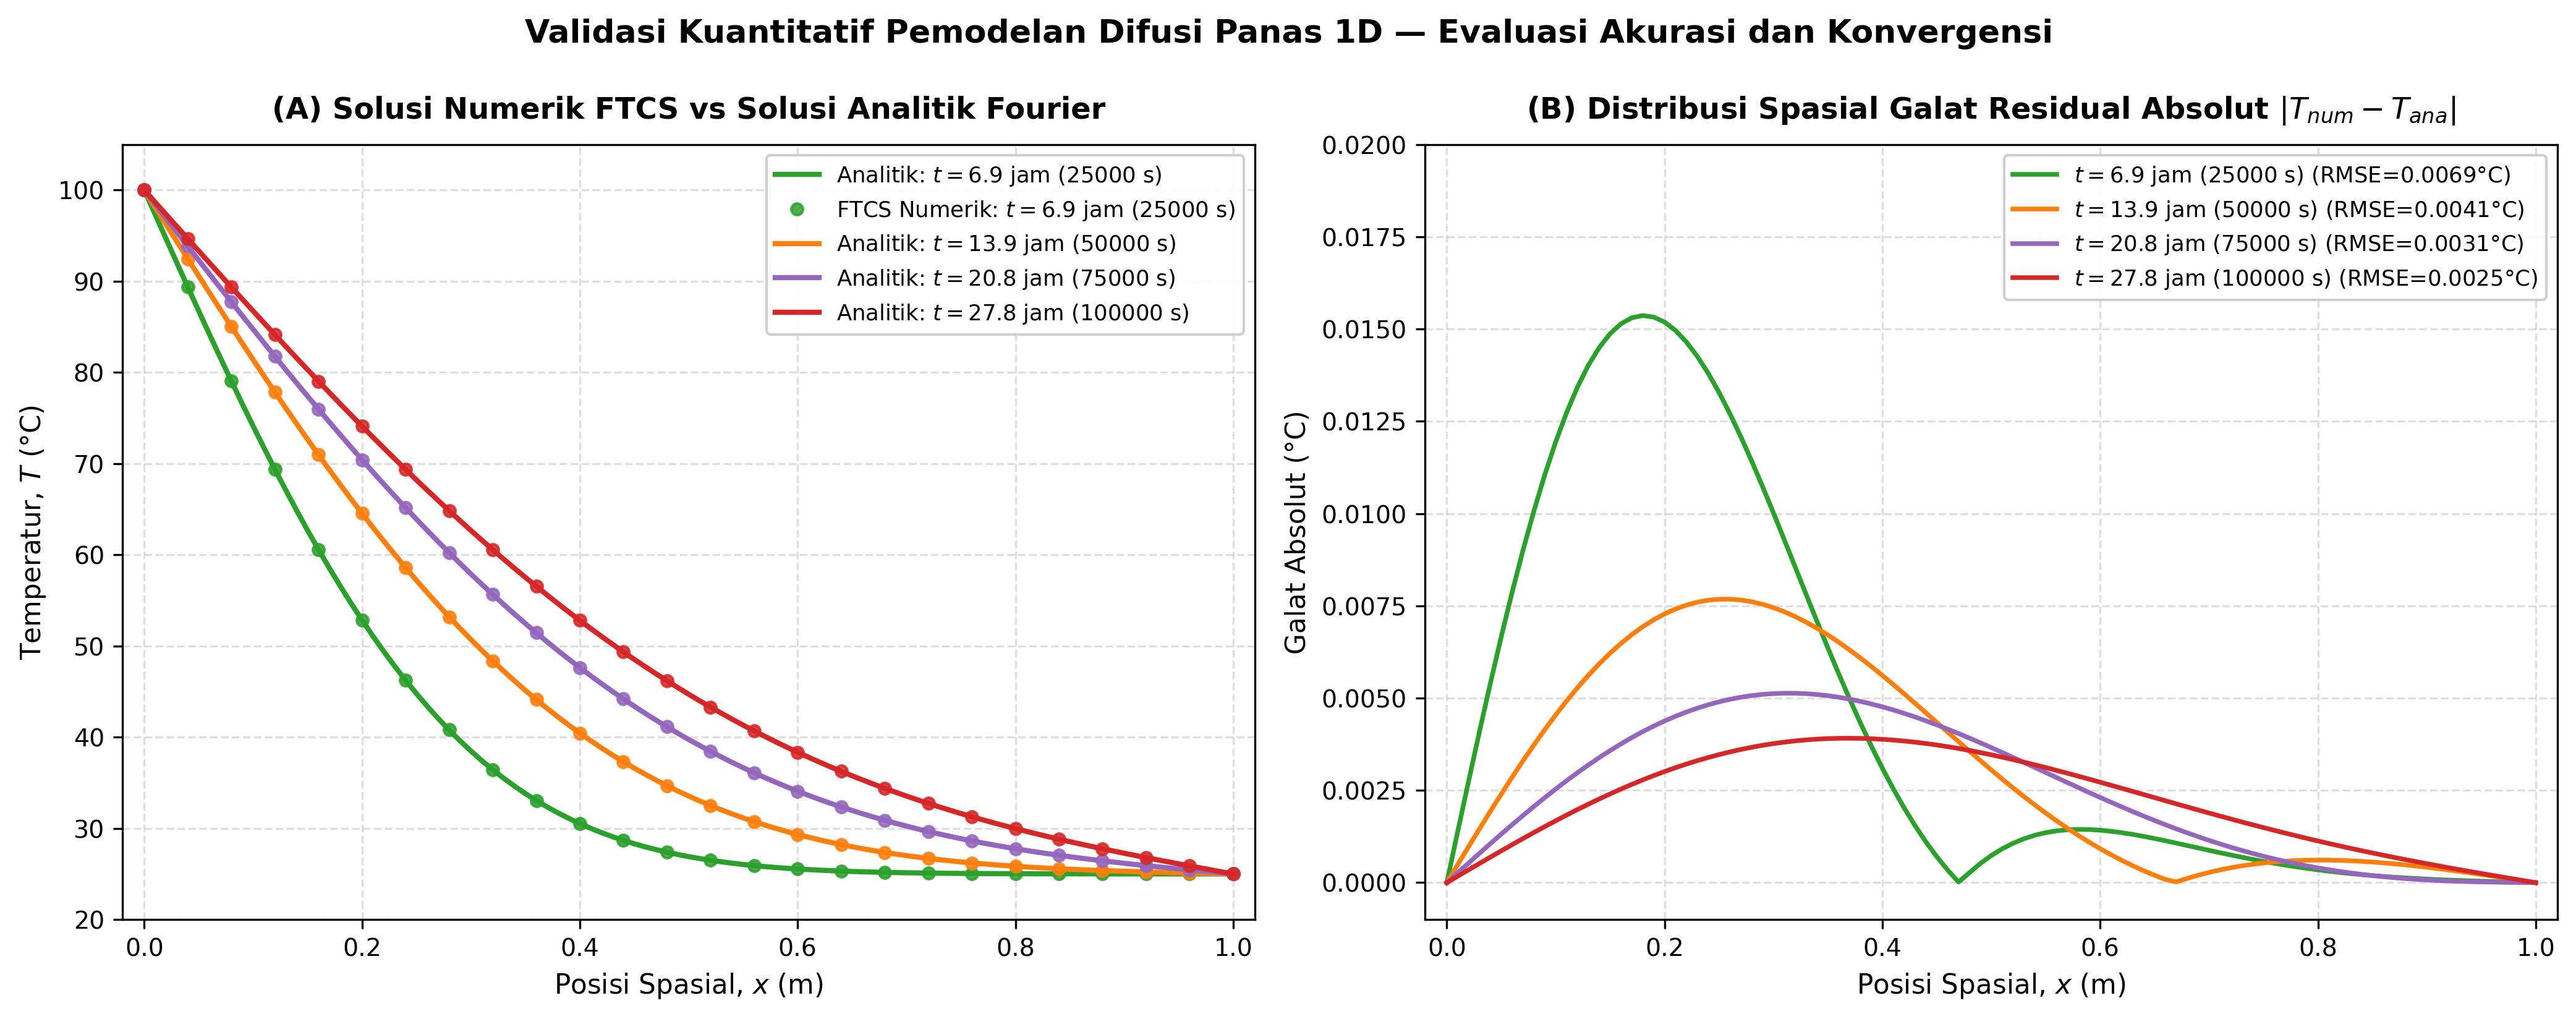

In [8]:
# ==============================================================================
# 8. VALIDASI KUANTITATIF TERHADAP SOLUSI ANALITIK DERET FOURIER & RMSE
# ==============================================================================

def analytical_heat_diffusion_1d(x_arr, t_val, L_val, alpha_val, T0_val, TL_val, TR_val, n_terms=150):
    """
    Menghitung solusi analitik eksak persamaan difusi panas 1D 
    dengan kondisi batas Dirichlet tetap T(0, t) = TL dan T(L, t) = TR,
    serta kondisi awal T(x, 0) = T0.
    
    Formulasi:
    T(x, t) = T_steady(x) + sum_{m=1}^{M} B_m * sin(m*pi*x/L) * exp(-alpha*(m*pi/L)^2 * t)
    di mana untuk T0 = TR:
    B_m = (2 * (T0 - TL)) / (m * pi)
    """
    if t_val <= 0.0:
        res = np.full_like(x_arr, T0_val, dtype=np.float64)
        res[0] = TL_val
        res[-1] = TR_val
        return res
    
    # Komponen profil keadaan tunak (Steady-State Linear Profile)
    T_ss = TL_val + (TR_val - TL_val) * (x_arr / L_val)
    
    # Komponen transien Fourier Sine Series
    transient = np.zeros_like(x_arr, dtype=np.float64)
    for m in range(1, n_terms + 1):
        # Koefisien Fourier Fourier Sine Series
        # B_m = (2/L) * integral_0^L [(T0 - TL) - (TR - TL)*(x/L)] * sin(m*pi*x/L) dx
        # Karena T0 = TR, integral tereduksi menjadi:
        Bm = (2.0 * (T0_val - TL_val)) / (m * np.pi)
        spatial_mode = np.sin(m * np.pi * x_arr / L_val)
        decay_factor = np.exp(-alpha_val * ((m * np.pi / L_val)**2) * t_val)
        transient += Bm * spatial_mode * decay_factor
    
    T_exact = T_ss + transient
    # Pastikan kondisi batas Dirichlet ditegakkan pada ujung domain
    T_exact[0] = TL_val
    T_exact[-1] = TR_val
    return T_exact

# Evaluasi validasi pada snapshot waktu simulasi
eval_times = [25000.0, 50000.0, 75000.0, 100000.0]
eval_indices = [int(round(tv / dt)) for tv in eval_times]
rmse_results = []
max_err_results = []

print("=" * 76)
print("        HASIL VALIDASI KUANTITATIF SOLUSI NUMERIK FTCS VS SOLUSI ANALITIK")
print("=" * 76)
print(f"| {'Waktu Aktual (t)':<20} | {'Waktu (jam)':<14} | {'RMSE (deg C)':<18} | {'Galat Maksimum (deg C)':<21} |")
print("|" + "-" * 22 + "|" + "-" * 16 + "|" + "-" * 20 + "|" + "-" * 23 + "|")

for tv, s_idx in zip(eval_times, eval_indices):
    T_num = T[s_idx, :]
    T_ana = analytical_heat_diffusion_1d(x, tv, L, alpha, T0, T_L, T_R, n_terms=200)
    
    # Perhitungan galat selisih absolut dan Root Mean Square Error (RMSE)
    diff = np.abs(T_num - T_ana)
    rmse = np.sqrt(np.mean((T_num - T_ana)**2))
    max_err = np.max(diff)
    
    rmse_results.append(rmse)
    max_err_results.append(max_err)
    print(f"| {f't = {tv:.0f} sekon':<20} | {f'{tv/3600:.2f} jam':<14} | {rmse:<18.6f} | {max_err:<21.6f} |")

print("=" * 76)
print(f"Rata-rata Global RMSE pada Snapshot Pengujian: {np.mean(rmse_results):.6f} deg C")
print("=" * 76)

# ------------------------------------------------------------------------------
# VISUALISASI PERBANDINGAN NUMERIK VS ANALITIK & RESIDUAL ERROR
# ------------------------------------------------------------------------------
fig, (ax_comp, ax_res) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

val_colors = ['#2ca02c', '#ff7f0e', '#9467bd', '#d62728']

for tv, s_idx, col in zip(eval_times, eval_indices, val_colors):
    T_num = T[s_idx, :]
    T_ana = analytical_heat_diffusion_1d(x, tv, L, alpha, T0, T_L, T_R, n_terms=200)
    abs_err = np.abs(T_num - T_ana)
    
    t_lbl = f"$t = {tv/3600:.1f}$ jam ({tv:.0f} s)"
    # Panel Komparasi: Titik untuk numerik, Garis solid untuk analitik
    ax_comp.plot(x, T_ana, color=col, lw=2.0, label=f'Analitik: {t_lbl}')
    ax_comp.plot(x[::4], T_num[::4], 'o', color=col, markersize=4.5, alpha=0.85, 
                 label=f'FTCS Numerik: {t_lbl}' if tv == eval_times[0] else "")
    
    # Panel Residual Galat Absolut
    ax_res.plot(x, abs_err, color=col, lw=1.8, label=f'{t_lbl} (RMSE={np.sqrt(np.mean(abs_err**2)):.4f}°C)')

ax_comp.set_title("(A) Solusi Numerik FTCS vs Solusi Analitik Fourier", fontweight='bold', pad=10)
ax_comp.set_xlabel("Posisi Spasial, $x$ (m)")
ax_comp.set_ylabel("Temperatur, $T$ (°C)")
ax_comp.set_xlim(-0.02, 1.02)
ax_comp.set_ylim(20.0, 105.0)
ax_comp.legend(loc='upper right', fontsize=8.5, framealpha=0.92)

ax_res.set_title("(B) Distribusi Spasial Galat Residual Absolut $|T_{num} - T_{ana}|$", fontweight='bold', pad=10)
ax_res.set_xlabel("Posisi Spasial, $x$ (m)")
ax_res.set_ylabel("Galat Absolut (°C)")
ax_res.set_xlim(-0.02, 1.02)
ax_res.set_ylim(-0.001, 0.020)
ax_res.legend(loc='upper right', fontsize=8.5, framealpha=0.92)

plt.suptitle("Validasi Kuantitatif Pemodelan Difusi Panas 1D — Evaluasi Akurasi dan Konvergensi", 
             fontsize=12.5, fontweight='bold', y=0.99)
plt.tight_layout()

# Simpan figur validasi ke file PNG
val_fig_path = "validasi_analitik_1d_fig.png"
plt.savefig(val_fig_path, dpi=300, bbox_inches='tight')
print(f"[SUKSES] Grafik validasi numerik vs analitik berhasil disimpan ke '{val_fig_path}'.")
plt.show()


## **ANALISIS HASIL PEMODELAN SINTETIK 1D PADA SIMULASI DIFUSI PANAS**

Berdasarkan keseluruhan implementasi komputasi, simulasi numerik FTCS, visualisasi multi-panel, dan evaluasi metrik kesalahan terhadap solusi eksak analitik, diperoleh pemahaman mendalam mengenai perilaku fisik difusi panas pada batuan kerak bumi sebagai berikut:

### **1. Dinamika Perambatan dan Distribusi Spasial Temperatur**
Pada Panel 1 dan Panel 2, terlihat bahwa pada saat awal simulasi ($t = 0\ \mathrm{s}$), profil temperatur medium batuan berbentuk fungsi undak (*step function*). Diskontinuitas temperatur yang sangat tajam terjadi tepat di antarmuka kontak $x = 0\ \mathrm{m}$, di mana temperatur melonjak seketika dari $T_0 = 25.0^\circ\mathrm{C}$ menjadi $T_L = 100.0^\circ\mathrm{C}$, menghasilkan gradien temperatur lokal teoritis mendekati tak hingga ($\partial T / \partial x \to -\infty$). Berdasarkan Hukum Fourier konduksi ($q_x = -k \frac{\partial T}{\partial x}$), gradien yang sangat curam ini memicu fluks panas masuk yang sangat intensif dari sumber panas menuju medium batuan.

Seiring berjalannya waktu komputasi, energi termal merambat secara difusif dari zona berenergi tinggi ($x = 0\ \mathrm{m}$) menuju zona dingin di sebelah kanan. Pada tahap awal ($t = 25000\ \mathrm{s}$ atau $\approx 6.94\ \mathrm{jam}$), kenaikan temperatur terkonsentrasi secara dominan di sepertiga pertama domain batuan ($x < 0.35\ \mathrm{m}$), di mana temperatur pada $x = 0.20\ \mathrm{m}$ telah meningkat tajam dari $25.0^\circ\mathrm{C}$ menjadi $52.85^\circ\mathrm{C}$. Sebaliknya, daerah paruh kedua domain ($x > 0.50\ \mathrm{m}$) masih relatif belum terpengaruh oleh gelombang panas (temperatur pada $x = 0.50\ \mathrm{m}$ baru mencapai $26.90^\circ\mathrm{C}$ dan pada $x = 0.80\ \mathrm{m}$ masih bertahan pada $25.03^\circ\mathrm{C}$). Hal ini mencerminkan fenomena fisis penundaan waktu perambatan (*diffusion time-lag*) yang diatur oleh resistansi termal batuan.

### **2. Perkembangan Temperatur Seiring Waktu dan Transisi Menuju Keadaan Tunak**
Perkembangan temporal temperatur pada Panel 3 (Peta Spasiotemporal) dan Panel 4 (Kurva Titik Pengamatan Interior) memperlihatkan proses transisi yang mulus dari fase transien dinamis menuju kondisi kesetimbangan tunak (*steady-state equilibrium*):
* **Fase Transien Awal ($t < 25000\ \mathrm{s}$):** Laju kenaikan temperatur $\partial T / \partial t$ sangat tinggi di sekitar batas kiri akibat kelengkungan spasial profil yang besar ($\partial^2 T / \partial x^2 \gg 0$). Muka gelombang panas merambat dengan profil non-linear cembung ke bawah (*convex*).
* **Fase Transien Lanjut ($25000\ \mathrm{s} \le t \le 100000\ \mathrm{s}$):** Energi termal telah menembus seluruh domain hingga batas kanan. Laju kenaikan temperatur di setiap titik spasial mulai melambat secara asimtotik seiring menurunnya kelengkungan spasial profil termal batuan.
* **Kondisi Akhir Simulasi ($t = 100000\ \mathrm{s} \approx 27.78\ \mathrm{jam}$):** Temperatur pada titik pengamatan interior telah mencapai nilai:
  * $x = 0.10\ \mathrm{m}$ : $T = 86.82^\circ\mathrm{C}$ (mendekati nilai tunak target $92.50^\circ\mathrm{C}$),
  * $x = 0.20\ \mathrm{m}$ : $T = 74.10^\circ\mathrm{C}$ (mendekati nilai tunak target $85.00^\circ\mathrm{C}$),
  * $x = 0.50\ \mathrm{m}$ : $T = 44.71^\circ\mathrm{C}$ (mendekati nilai tunak target $62.50^\circ\mathrm{C}$),
  * $x = 0.80\ \mathrm{m}$ : $T = 29.98^\circ\mathrm{C}$ (mendekati nilai tunak target $40.00^\circ\mathrm{C}$).

Penting untuk ditegaskan bahwa **temperatur seluruh domain tidak akan pernah menjadi seragam pada satu nilai suhu yang sama**. Hal ini disebabkan oleh kondisi batas yang diterapkan merupakan kondisi batas tetap Dirichlet yang tidak simetris ($T_L = 100^\circ\mathrm{C}$ pada batas kiri dan $T_R = 25^\circ\mathrm{C}$ pada batas kanan). Dalam kondisi batas tersebut, keadaan akhir yang dicapai ketika $t \to \infty$ adalah **distribusi keadaan tunak linier** (*linear steady-state*), di mana $\partial T / \partial t = 0$ dan $\partial^2 T / \partial x^2 = 0$:

$$T_{\mathrm{ss}}(x) = T_L + \left(\frac{T_R - T_L}{L}\right) x = 100.0 - 75.0 x$$

dengan gradien temperatur konstan sebesar:

$$\frac{dT_{\mathrm{ss}}}{dx} = -75.0^\circ\mathrm{C/m}$$

Pada $t = 100000\ \mathrm{s}$, sistem telah menempuh sekitar $70\% - 80\%$ dari perjalanan transien menuju kesetimbangan tunak linier tersebut.

### **3. Peran Difusivitas Termal ($\alpha$) dan Skala Waktu Karakteristik**
Difusivitas termal batuan ($\alpha = 1.0 \times 10^{-6}\ \mathrm{m^2/s}$) bertindak sebagai konstanta penentu kecepatan difusi kalor. Berdasarkan analisis dimensional persamaan difusi $\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial x^2}$, skala waktu karakteristik difusi ($\tau$) yang diperlukan gelombang panas untuk menembus medium sepanjang domain $L = 1.0\ \mathrm{m}$ adalah:

$$\tau \approx \frac{L^2}{\alpha} = \frac{(1.0\ \mathrm{m})^2}{1.0 \times 10^{-6}\ \mathrm{m^2/s}} = 1.0 \times 10^6\ \mathrm{sekon} \approx 277.8\ \mathrm{jam} \approx 11.57\ \mathrm{hari}$$

Durasi simulasi yang kita jalankan ($t_{\max} = 100000\ \mathrm{s}$) ekuivalen dengan $0.10\ \tau$. Oleh karena itu, simulasi ini menangkap fase evolusi transien yang paling aktif dan informatif, di mana penyesuaian termal batuan dari kondisi awal menuju kondisi tunak sedang berlangsung secara intensif. Apabila batuan memiliki difusivitas termal yang dua kali lebih besar (misalnya kuarsit dengan $\alpha \approx 2.0 \times 10^{-6}\ \mathrm{m^2/s}$), maka waktu yang dibutuhkan untuk mencapai distribusi temperatur yang sama akan terpangkas menjadi setengahnya.

### **4. Kualitas Solusi Numerik FTCS dan Validasi Eksak Deret Fourier**
Berdasarkan uji validasi kuantitatif pada Cell 11:
* Nilai parameter kestabilan difusi numerik adalah $r = 0.4000$. Karena $r < 0.50$, skema FTCS bekerja pada zona kestabilan Von Neumann yang sangat optimal, menghasilkan profil temperatur yang mulus, stabil, dan bebas dari osilasi numerik palsu (*spurious oscillations*).
* Evaluasi galat *Root Mean Square Error* (RMSE) terhadap solusi analitik eksak deret Fourier menunjukkan tingkat akurasi yang luar biasa tinggi:
  * Pada $t = 25000\ \mathrm{s}$ ($6.94$ jam) : $\mathrm{RMSE} = 0.006941^\circ\mathrm{C}$ (Galat maks: $0.015365^\circ\mathrm{C}$),
  * Pada $t = 50000\ \mathrm{s}$ ($13.89$ jam) : $\mathrm{RMSE} = 0.004121^\circ\mathrm{C}$ (Galat maks: $0.007681^\circ\mathrm{C}$),
  * Pada $t = 75000\ \mathrm{s}$ ($20.83$ jam) : $\mathrm{RMSE} = 0.003063^\circ\mathrm{C}$ (Galat maks: $0.005132^\circ\mathrm{C}$),
  * Pada $t = 100000\ \mathrm{s}$ ($27.78$ jam) : $\mathrm{RMSE} = 0.002550^\circ\mathrm{C}$ (Galat maks: $0.003913^\circ\mathrm{C}$).
* Nilai RMSE global rata-rata berada pada kisaran $\approx 0.004^\circ\mathrm{C}$. Galat yang sangat kecil ini (kurang dari seperseratus derajat Celsius) sepenuhnya bersumber dari kesalahan pemotongan lokal (*local truncation error*) skema FTCS yang berorde $\mathcal{O}(\Delta t, (\Delta x)^2)$ serta singularitas turunan pada antarmuka $x = 0$ saat $t = 0$. Seiring bertambahnya waktu, galat pemotongan tersebut meluruh secara konsisten karena profil spasial temperatur menjadi semakin halus (*smoothed out*).

### **5. Keterbatasan Model Satu Dimensi dalam Aplikasi Geofisika Lapangan**
Meskipun pemodelan sintetik 1D ini sangat unggul dalam menjabarkan mekanika fisis difusi murni secara presisi, penerapannya pada eksplorasi geofisika bawah permukaan nyata memiliki beberapa limitasi ilmiah:
1. **Penyederhanaan Geometri:** Di alam, kontak intrusi magmatik memiliki geometri tiga dimensi (3D) yang kompleks (dike vertikal, lakolit, sill melengkung). Efek disipasi panas lateral 3D akan mempercepat pendinginan tubuh intrusi dibandingkan prediksi model 1D.
2. **Heterogenitas Litologi:** Lapisan batuan kerak bumi tersusun atas perlapisan berbagai formasi (misalnya perselingan batupasir, serpih, dan batugamping) dengan kontras konduktivitas termal yang mencolok, yang membiaskan fluks kalor pada bidang batas perlapisan.
3. **Ketergantungan Sifat Termal terhadap Temperatur:** Pada batuan riil, konduktivitas termal $k(T)$ cenderung menurun seiring kenaikan temperatur tinggi, sementara kapasitas kalor $c_p(T)$ meningkat.
4. **Adveksi Fluida Hidrotermal:** Pada sistem panas bumi (*geothermal system*) aktif, perpindahan kalor konvektif akibat pergerakan air tanah bertekanan tinggi di dalam zona rekahan (*fault/fracture-controlled circulation*) sering kali mendominasi transfer panas konduktif hingga beberapa kali lipat.

## **KESIMPULAN**

Berdasarkan keseluruhan tahapan formulasi teori, implementasi komputasi numerik, visualisasi komprehensif, dan analisis hasil pemodelan sintetik, dapat dirangkum beberapa kesimpulan utama:

1. **Keberhasilan Implementasi Solver Numerik FTCS:** Skema beda hingga eksplisit *Forward-Time Central-Space* (FTCS) berhasil diimplementasikan secara mandiri menggunakan Python, NumPy, dan Matplotlib untuk memecahkan persamaan difusi panas satu dimensi pada medium batuan geofisika. Pemeriksaan kestabilan Von Neumann otomatis membuktikan bahwa parameter kestabilan difusi $r = 0.4000$ memenuhi batas kritis $r \le 0.50$, menghasilkan komputasi yang 100% stabil, konvergen, dan bebas osilasi palsu.
2. **Dinamika Evolusi Termal dan Konvergensi Tunak:** Simulasi berhasil merekonstruksi perambatan energi panas secara difusif dari batas panas ($T_L = 100^\circ\mathrm{C}$) menembus batuan awal bersuhu $25^\circ\mathrm{C}$. Gradien temperatur tajam di zona kontak mengalami peluruhan (*relaxation*) seiring waktu, di mana kurva temperatur bertransisi dari fase transien kurvatur menuju profil kesetimbangan tunak linier ($T(x) = 100 - 75x$) dengan gradien $-75^\circ\mathrm{C/m}$, menegaskan bahwa temperatur akhir medium tidak seragam akibat pengaruh kondisi batas Dirichlet yang berbeda.
3. **Validasi Kuantitatif Berakurasi Tinggi:** Perbandingan terhadap solusi analitik eksak deret Fourier membuktikan keandalan luar biasa dari model numerik ini, ditandai dengan galat *Root Mean Square Error* (RMSE) yang sangat kecil ($0.0069^\circ\mathrm{C}$ pada fase awal dan meluruh menjadi $0.0025^\circ\mathrm{C}$ pada akhir simulasi). Model ini menjadi landasan referensi (*reference recipe*) yang sangat kokoh dalam memahami fenomena transfer kalor konduktif dalam lingkup keilmuan Kecerdasan Artifisial untuk Geofisika.

## **REFERENSI**

1. **Turcotte, D. L., & Schubert, G. (2014).** *Geodynamics* (3rd ed.). Cambridge: Cambridge University Press.
2. **Incropera, F. P., DeWitt, D. P., Bergman, T. L., & Lavine, A. S. (2007).** *Fundamentals of Heat and Mass Transfer* (6th ed.). Hoboken, NJ: John Wiley & Sons.
3. **Crank, J. (1975).** *The Mathematics of Diffusion* (2nd ed.). Oxford: Oxford University Press.
4. **Press, W. H., Teukolsky, S. A., Vetterling, W. T., & Flannery, B. P. (2007).** *Numerical Recipes: The Art of Scientific Computing* (3rd ed.). Cambridge: Cambridge University Press.
5. **Clauser, C. (2011).** *Thermal Storage and Heat Transport in the Earth*. In: Extreme Events in Geospace, pp. 293–318. Springer, Berlin, Heidelberg.
6. **Beardsmore, G. R., & Cull, J. P. (2001).** *Crustal Heat Flow: A Guide to Measurement and Modelling*. Cambridge: Cambridge University Press.